<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch 1/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.1272 - val_loss: 0.0509
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0360 - val_loss: 0.0191
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0184 - val_loss: 0.0113
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0127 - val_loss: 0.0100
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0113 - val_loss: 0.0093
MAE: 4.8860141134967705
RMSE: 6.0605719136517235


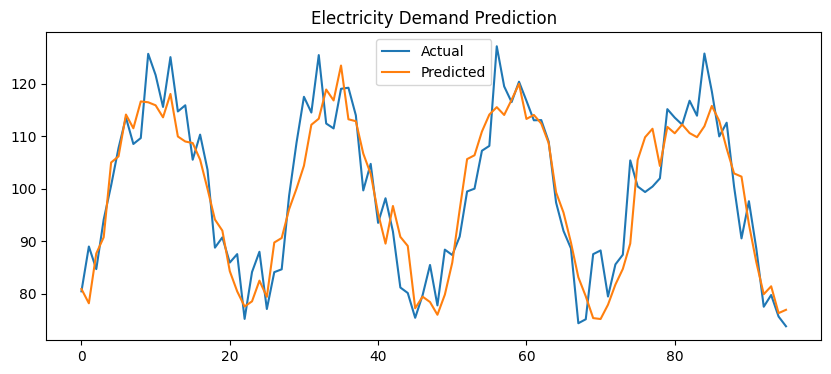

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Generate small electricity demand dataset
np.random.seed(42)
data = 100 + 20 * np.sin(np.arange(500) * 2 * np.pi / 24) \
       + np.random.normal(0, 5, 500)

df = pd.DataFrame({'Demand': data})
df['Demand'] = df['Demand'].interpolate()

scaler = MinMaxScaler()
scaled = scaler.fit_transform(df[['Demand']])

# Create sequences
X, y = [], []
for i in range(len(scaled) - 24):
    X.append(scaled[i:i+24])
    y.append(scaled[i+24])

X, y = np.array(X), np.array(y)

# Chronological split
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# SimpleRNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(24, 1)),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
history = model.fit(
    X_train, y_train, epochs=5,
    batch_size=32, validation_split=0.2
)

# Predict
pred = model.predict(X_test, verbose=0)
actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(pred)

print("MAE:", mean_absolute_error(actual, predicted))
print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))

plt.figure(figsize=(10, 4))
plt.plot(actual, label='Actual')
plt.plot(predicted, label='Predicted')
plt.title("Electricity Demand Prediction")
plt.legend()
plt.show()